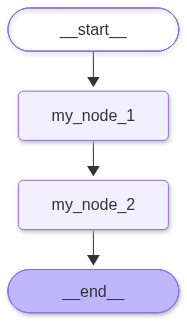

In [4]:
from typing import TypedDict

from IPython.core.display import Image
from langgraph.constants import START, END
from langgraph.graph import StateGraph


# 1. State
class MyState(TypedDict):
    name: str
    message: str


# 2. Node
def my_node_1(state: MyState):
    print(f"开始执行my_node_1，state: {state}")
    return {
        "message": f"hello, {state.get("name")}"
    }


def my_node_2(state: MyState):
    print(f"开始执行my_node_2，state: {state}")
    return {
        "message": state.get("message").upper()
    }


# 3. Edge
builder = StateGraph(MyState)

builder.add_node("my_node_1", my_node_1)
builder.add_node("my_node_2", my_node_2)

builder.add_edge(START, "my_node_1")
builder.add_edge("my_node_1", "my_node_2")
builder.add_edge("my_node_1", END)

graph = builder.compile()

display(Image(graph.get_graph(xray=True).draw_mermaid_png()))

In [11]:
res_state = graph.invoke({"name": "hxl"})

print(f"res_state = {res_state}")

开始执行my_node_1，state: {'name': 'hxl'}
开始执行my_node_2，state: {'name': 'hxl', 'message': 'hello, hxl'}
res_state = {'name': 'hxl', 'message': 'HELLO, HXL'}
